CORRELATION OF EACH COLUMN WITH state_of_health_%
cycle_number                 -0.8907
calendar_age_days            -0.8907
resistance_growth_%          -0.6990
internal_resistance_mOhm     -0.6990
cell_temperature_C           -0.0149
ambient_temperature_C        -0.0051
voltage_V                    -0.0062
current_A                     0.0016
state_of_charge_%            -0.0574
safety_margin_index           0.0035
thermal_runaway_risk_index   -0.0046
heat_generation_W            -0.0590
energy_throughput_kWh        -0.0552
degradation_rate_%           -0.4242
Name: state_of_health_%, dtype: float64

Simple regression predictor  : cycle_number
Multiple regression predictors: ['cycle_number', 'calendar_age_days', 'internal_resistance_mOhm']

NULL VALUES AFTER CREATING MISSING DATA
10000 missing out of 100000

SIMPLE LINEAR REGRESSION
Equation: state_of_health_% = 99.993017 + -0.012327 * cycle_number
MAE = 1.413839 | RMSE = 1.807251 | R2 = 0.792857

MULTIPLE LINEAR REGRESSION
Intercept 

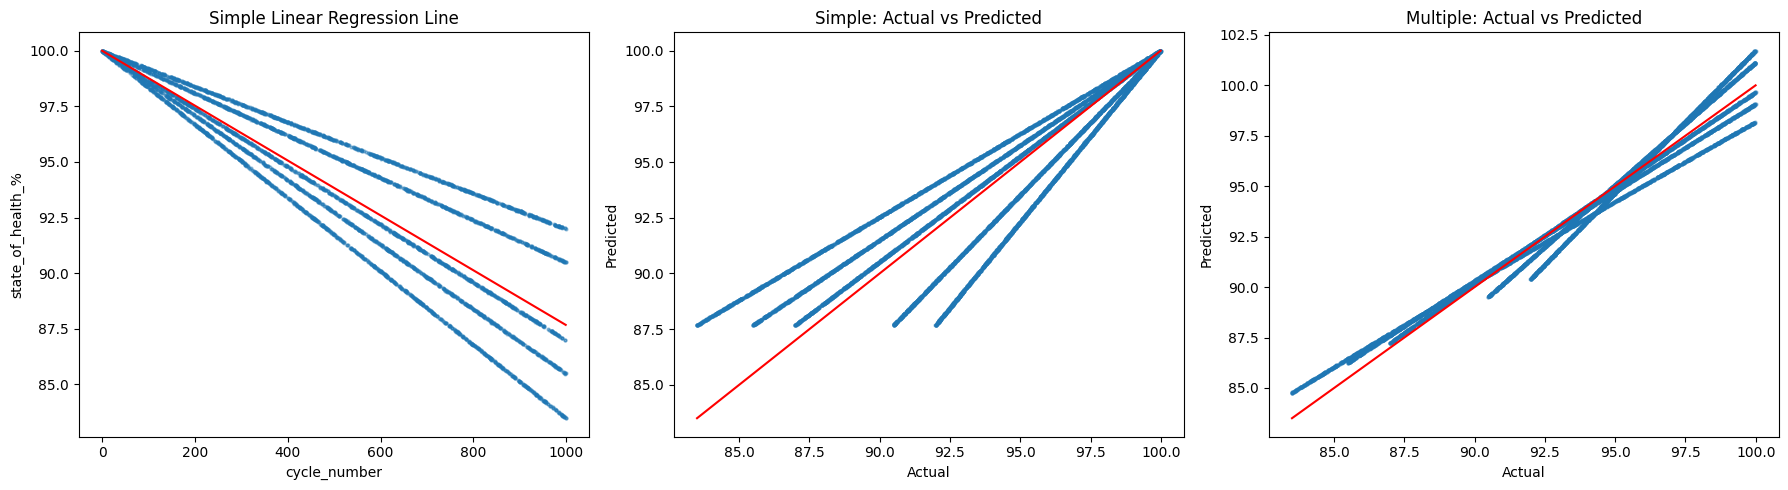

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Load dataset (random sample of 100000 rows keeps it fast)
df = pd.read_csv(r"C:\Users\Chetan\Downloads\archive\synthetic_ev_battery_5year_50cols_multimfg_3M.csv")
data = df.sample(n=100000, random_state=42).reset_index(drop=True)

# STEP 1: Identify suitable attributes using correlation
candidates = [
    "cycle_number", "calendar_age_days", "state_of_health_%", "capacity_fade_%",
    "resistance_growth_%", "internal_resistance_mOhm", "cell_temperature_C",
    "ambient_temperature_C", "voltage_V", "current_A", "state_of_charge_%",
    "safety_margin_index", "thermal_runaway_risk_index", "heat_generation_W",
    "energy_throughput_kWh", "degradation_rate_%"
]
candidates = [c for c in candidates if c in data.columns and data[c].std() > 0]

target = "state_of_health_%"            # column in which values will go missing

corr_with_target = data[candidates].corr()[target].drop(target)
corr_with_target = corr_with_target[corr_with_target.abs() < 0.99]   # skip near-duplicate columns
ranked = corr_with_target.abs().sort_values(ascending=False)

simple_x = ranked.index[0]              # best single predictor
multi_x = list(ranked.index[:3])        # best three predictors

print("CORRELATION OF EACH COLUMN WITH", target)
print(corr_with_target.round(4))
print("\nSimple regression predictor  :", simple_x)
print("Multiple regression predictors:", multi_x)

# STEP 2: Create missing values (10% of target column)
np.random.seed(42)
missing_idx = np.random.choice(data.index, size=int(0.10 * len(data)), replace=False)
actual = data.loc[missing_idx, target].values        # true values kept for checking

data_missing = data.copy()
data_missing.loc[missing_idx, target] = np.nan

print("\nNULL VALUES AFTER CREATING MISSING DATA")
print(data_missing[target].isnull().sum(), "missing out of", len(data_missing))

train = data_missing.dropna(subset=[target])          # rows with known target
test = data_missing.loc[missing_idx]                  # rows to be predicted

# STEP 3: Functions (no built-in prediction package)
def simple_linear_regression(x, y):
    # w1 = sum((xi-xbar)(yi-ybar)) / sum((xi-xbar)^2) ; w0 = ybar - w1*xbar
    x_mean, y_mean = x.mean(), y.mean()
    w1 = np.sum((x - x_mean) * (y - y_mean)) / np.sum((x - x_mean) ** 2)
    w0 = y_mean - w1 * x_mean
    return w0, w1

def multiple_linear_regression(X, y):
    # b = (X^T X)^-1 X^T Y
    Xb = np.column_stack([np.ones(len(X)), X])
    b = np.linalg.inv(Xb.T @ Xb) @ (Xb.T @ y)
    return b

def predict_multiple(X, b):
    return np.column_stack([np.ones(len(X)), X]) @ b

def evaluate(actual, pred):
    err = actual - pred
    mae = np.mean(np.abs(err))
    rmse = np.sqrt(np.mean(err ** 2))
    r2 = 1 - np.sum(err ** 2) / np.sum((actual - actual.mean()) ** 2)
    return mae, rmse, r2

# MODEL 1: Simple linear regression
x_train = train[simple_x].values
y_train = train[target].values
w0, w1 = simple_linear_regression(x_train, y_train)

pred_simple = w0 + w1 * test[simple_x].values
print("\nSIMPLE LINEAR REGRESSION")
print(f"Equation: {target} = {w0:.6f} + {w1:.6f} * {simple_x}")
mae1, rmse1, r2_1 = evaluate(actual, pred_simple)
print(f"MAE = {mae1:.6f} | RMSE = {rmse1:.6f} | R2 = {r2_1:.6f}")

# MODEL 2: Multiple linear regression
b = multiple_linear_regression(train[multi_x].values, y_train)
pred_multi = predict_multiple(test[multi_x].values, b)

print("\nMULTIPLE LINEAR REGRESSION")
print("Intercept b0 =", round(b[0], 6))
for name, coef in zip(multi_x, b[1:]):
    print(f"  coefficient of {name} = {coef:.6f}")
mae2, rmse2, r2_2 = evaluate(actual, pred_multi)
print(f"MAE = {mae2:.6f} | RMSE = {rmse2:.6f} | R2 = {r2_2:.6f}")

# MODEL 3: Polynomial (non-linear) regression, degree 2, for comparison
xp_train = np.column_stack([train[simple_x].values, train[simple_x].values ** 2])
xp_test = np.column_stack([test[simple_x].values, test[simple_x].values ** 2])
bp = multiple_linear_regression(xp_train, y_train)
pred_poly = predict_multiple(xp_test, bp)

print("\nPOLYNOMIAL REGRESSION (degree 2)")
mae3, rmse3, r2_3 = evaluate(actual, pred_poly)
print(f"MAE = {mae3:.6f} | RMSE = {rmse3:.6f} | R2 = {r2_3:.6f}")

# BASELINE: Mean imputation
pred_mean = np.full(len(actual), y_train.mean())
mae4, rmse4, r2_4 = evaluate(actual, pred_mean)

# STEP 4: Fill the missing values using the multiple regression model
data_imputed = data_missing.copy()
data_imputed.loc[missing_idx, target] = pred_multi
print("\nNULL VALUES AFTER REGRESSION IMPUTATION:", data_imputed[target].isnull().sum())

print("\nSAMPLE OF PREDICTED VS ACTUAL")
compare_sample = pd.DataFrame({
    "Actual": actual[:8],
    "Simple": pred_simple[:8],
    "Multiple": pred_multi[:8]
}).round(4)
print(compare_sample)

# STEP 5: Comparison of all models
comparison = pd.DataFrame({
    "Model": ["Mean imputation", "Simple linear", "Polynomial (deg 2)", "Multiple linear"],
    "MAE": [mae4, mae1, mae3, mae2],
    "RMSE": [rmse4, rmse1, rmse3, rmse2],
    "R2": [r2_4, r2_1, r2_3, r2_2]
}).round(6)
print("\nCOMPARISON OF ALL MODELS")
print(comparison.to_string(index=False))

# STEP 6: Plots
plot_part = train.sample(n=5000, random_state=1)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].scatter(plot_part[simple_x], plot_part[target], s=4, alpha=0.4)
xs = np.array([plot_part[simple_x].min(), plot_part[simple_x].max()])
axes[0].plot(xs, w0 + w1 * xs, color="red")
axes[0].set_title("Simple Linear Regression Line")
axes[0].set_xlabel(simple_x)
axes[0].set_ylabel(target)

for ax, pred, title in [(axes[1], pred_simple, "Simple: Actual vs Predicted"),
                        (axes[2], pred_multi, "Multiple: Actual vs Predicted")]:
    ax.scatter(actual, pred, s=4, alpha=0.4)
    lims = [actual.min(), actual.max()]
    ax.plot(lims, lims, color="red")       # perfect prediction line
    ax.set_title(title)
    ax.set_xlabel("Actual")
    ax.set_ylabel("Predicted")

plt.tight_layout()
plt.show()
